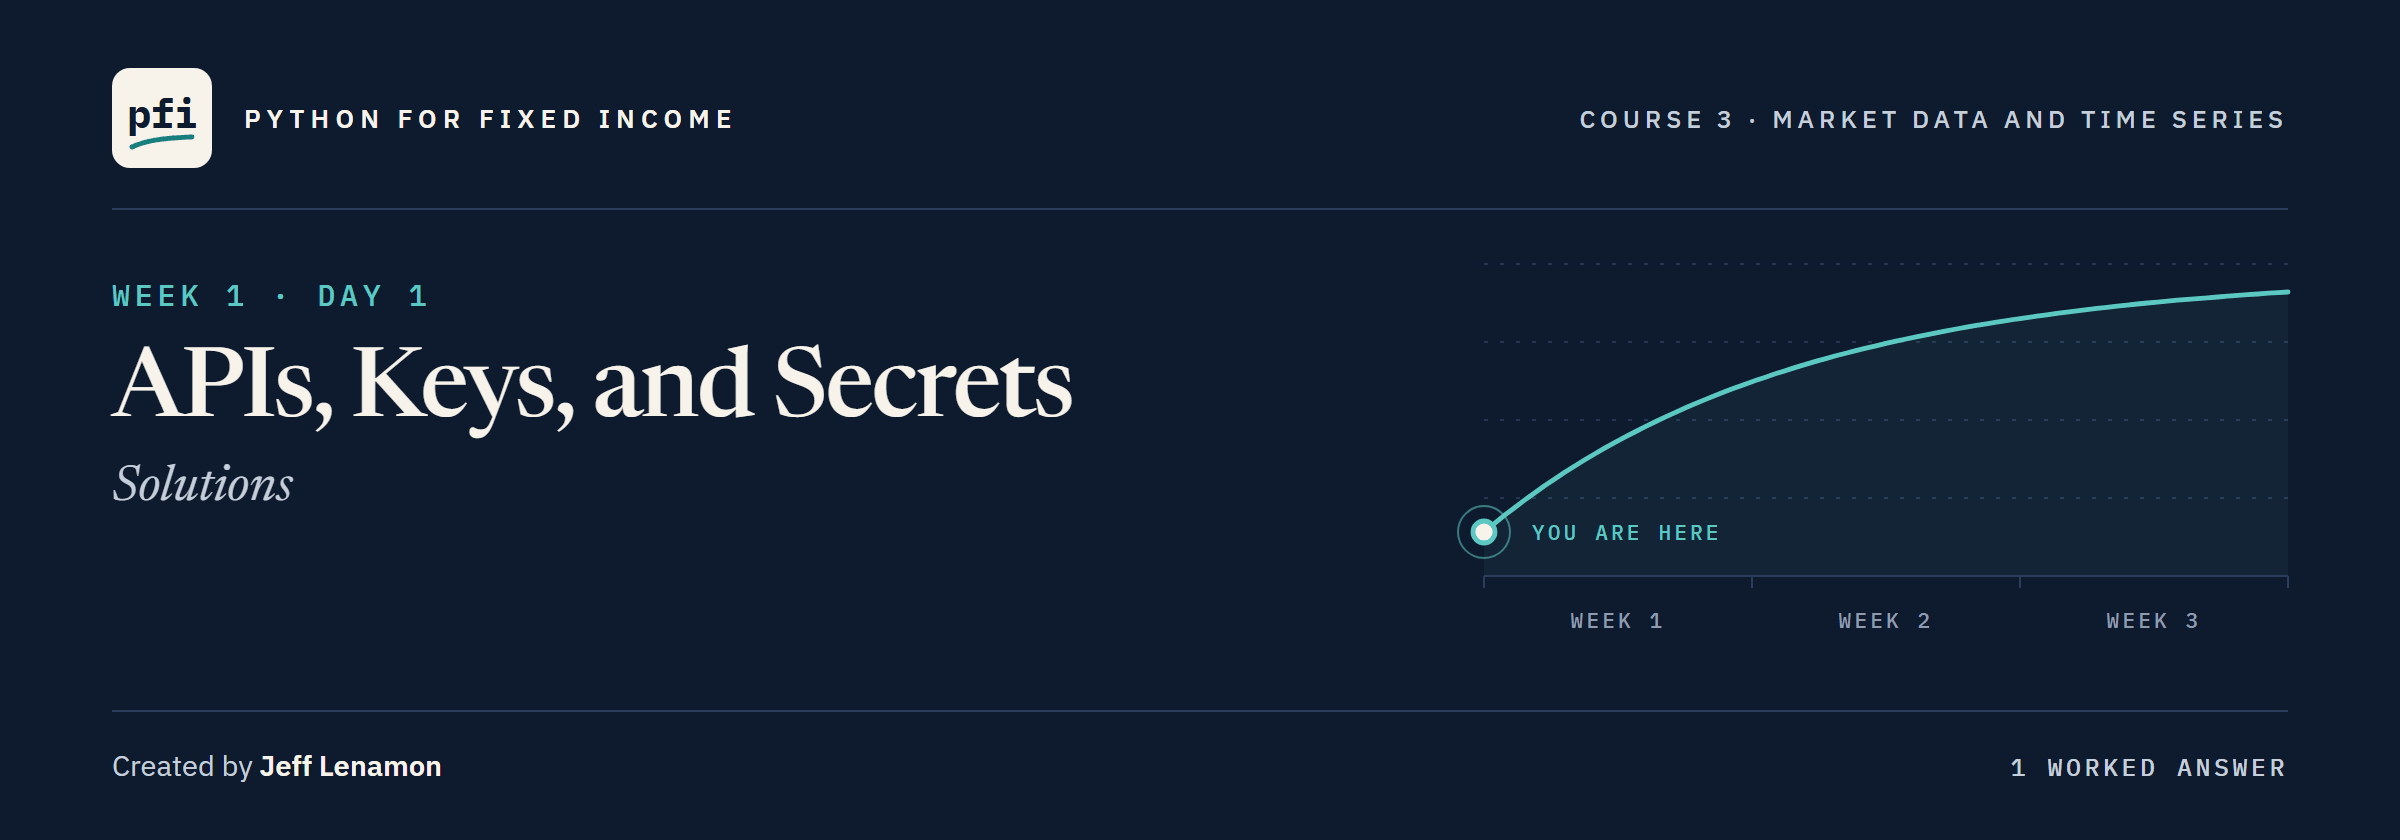

# APIs, Keys, and Secrets: Solutions

Week 1, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day1/01_apis_keys_and_secrets_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the drill file.

No key is needed.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 01 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(1, after=1)

Work folder pfi_course3_01_k4w7q2xr: 3 data files, Course 2's bondmath.py, marketdata.py as notebook 01 left it, 1 commit


In [2]:
import importlib

import marketdata as md

FAKE_KEY = 'fakefakefakefakefakefakefakefake'
FRED_URL = 'https://api.stlouisfed.org/fred/series/observations'
print('get_secret is in the module:', 'get_secret' in dir(md))

get_secret is in the module: True


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
%%writefile two_secrets.env
# two demo secrets, both fake
DEMO_API_KEY=fakefakefakefakefakefakefakefake
DEMO_DATA_TOKEN=second-demo-value

Writing two_secrets.env


### Exercise 1

In [5]:
ex1_value = md.get_secret('DEMO_DATA_TOKEN', env_file='two_secrets.env')
check('Exercise 1 the second secret', ex1_value, 'second-demo-value')

Exercise 1 the second secret: correct


No variable of that name and no Colab, so `get_secret` read the file; the name picks the line.

### Exercise 2

In [6]:
# prediction: the environment's value, because get_secret asks there first
os.environ['DEMO_API_KEY'] = 'value-from-the-environment'
ex2_value = md.get_secret('DEMO_API_KEY', env_file='two_secrets.env')
del os.environ['DEMO_API_KEY']
check('Exercise 2 the environment against the file', ex2_value, 'value-from-the-environment')

Exercise 2 the environment against the file: correct


The environment wins, as the docstring's order says.
It is why the demos never use the name `FRED_API_KEY`: on a machine with a real key in the environment, a demo under that name would get the real key back.

### Exercise 3

In [7]:
%%writefile -a marketdata.py


def env_example_text(names: list[str]) -> str:
    """The text of a .env.example file: one NAME= line for each secret name, every value left empty.

    Units: none; text in, text out. Convention: the names in the order given, each line ending in a newline,
    and no value ever written, so the file can be committed and tells a reader which secrets to set.
    Raises ValueError on an empty name, or a name with a space or an equals sign in it.
    """
    for name in names:
        if not name or " " in name or "=" in name:
            raise ValueError(f"not a secret name: {name!r}")
    return "".join([f"{name}=\n" for name in names])

Appending to marketdata.py


In [8]:
%%writefile -a test_marketdata.py


def test_env_example_text_has_names_and_no_values():
    text = md.env_example_text(["FRED_API_KEY", DEMO_NAME])
    assert text == "FRED_API_KEY=\nDEMO_API_KEY=\n"
    # a .env.example never holds a value
    assert FAKE_KEY not in text
    with pytest.raises(ValueError):
        md.env_example_text(["NOT A NAME"])

Appending to test_marketdata.py


In [9]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....                                                                    [100%]
5 passed in 0.50s



In [10]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_text = md.env_example_text(['FRED_API_KEY', 'DEMO_API_KEY'])
check('Exercise 3 the .env.example text', ex3_text, 'FRED_API_KEY=\nDEMO_API_KEY=\n')

Exercise 3 the .env.example text: correct


`ex3_text` is two lines with nothing after the `=`: committed, they tell anyone who copies the folder which secrets to set, without giving any away.

### Exercise 4: AI check

The bug: the line is built from the request's own parameters, key included, so it holds `api_key=` and the key.
Every log file it reaches would hold the key: the leak of 1.10, in slow motion.
The fix replaces the key with `***` before the line is built.

In [11]:
# written for this course in the style of an AI assistant's answer, now fixed
def describe_request(series_id, api_key):
    """Return one line describing a FRED request, safe to print and to write to a log file.

    Units: none; text out. Convention: the line names the endpoint and the series, and never
    holds the API key. A log line is read by people and kept in files, so the key is shown as ***.
    """
    # the fix: the key is replaced by *** before the line is built, so it can never reach the line
    params = {'series_id': series_id, 'api_key': '***', 'file_type': 'json'}
    query = '&'.join([f'{name}={value}' for name, value in params.items()])
    return f'GET {FRED_URL}?{query}'

In [12]:
# the test, written from the docstring before the code is trusted
line = describe_request('DGS10', FAKE_KEY)
assert 'DGS10' in line, 'the line does not name the series'
assert FAKE_KEY not in line, 'the log line holds the API key'
print('The line names the series and holds no key')

The line names the series and holds no key


In [13]:
# the fixed line: safe to print, because the key is ***
print(describe_request('DGS10', FAKE_KEY))

GET https://api.stlouisfed.org/fred/series/observations?series_id=DGS10&api_key=***&file_type=json


In [14]:
ex4_hides_key = FAKE_KEY not in describe_request('DGS10', FAKE_KEY)
ex4_names_series = 'DGS10' in describe_request('DGS10', FAKE_KEY)
check('Exercise 4 the line hides the key', ex4_hides_key, True)
check('Exercise 4 the line names the series', ex4_names_series, True)

Exercise 4 the line hides the key: correct
Exercise 4 the line names the series: correct


The line still says which request was made, and the key is `***`.
Move that test into `test_marketdata.py`, and the bug cannot come back unnoticed.

[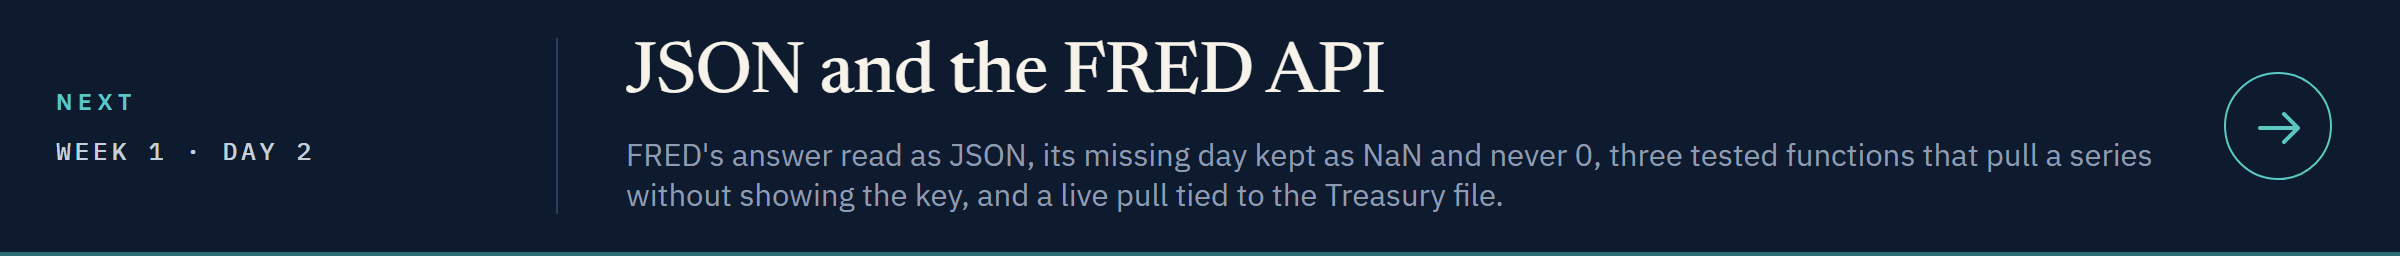](../day2/02_json_and_the_fred_api.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day2/02_json_and_the_fred_api.ipynb)